In [1]:
import torch
from rfdetr import RFDETRNano
# from rfdetr import RFDETRMedium
# from rfdetr import RFDETRLarge
# model = RFDETRNano()
# model = RFDETRMedium()
# model = RFDETRNano(pretrain_weights="./v2/checkpoint_best_total.pth", resolution=448)
model = RFDETRNano(pretrain_weights="./test/checkpoint_best_total.pt", resolution=448)


Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
Loading pretrain weights


In [2]:
model.optimize_for_inference()

`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


In [3]:
from PIL import Image
import supervision as sv

image = Image.open("./rfdetr_dataset/valid/1478020224197266285.jpg")
detections = model.predict(image)

val_ds = sv.DetectionDataset.from_coco(
    images_directory_path="rfdetr_dataset/valid",
    annotations_path="rfdetr_dataset/valid/_annotations.coco.json"
)

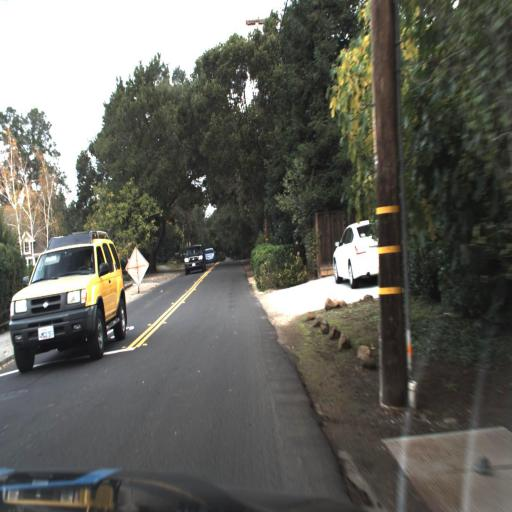

In [4]:
test_img = Image.open(val_ds[25][0])
test_img

In [5]:
import supervision as sv
from tqdm import tqdm
from supervision.metrics import MeanAveragePrecision

targets = []
predictions = []

for path, image, annotations in tqdm(val_ds):
    image = Image.open(path)
    detections = model.predict(image, threshold=0)

    targets.append(annotations)
    predictions.append(detections)

100%|██████████| 2250/2250 [02:51<00:00, 13.13it/s]


In [12]:
map_metric = MeanAveragePrecision()
map_result = map_metric.update(predictions, targets).compute()
print(map_result)

Average Precision (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.449
Average Precision (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.826
Average Precision (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.428
Average Precision (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.401
Average Precision (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ]                 = 0.591
Average Precision (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ]                 = 0.754


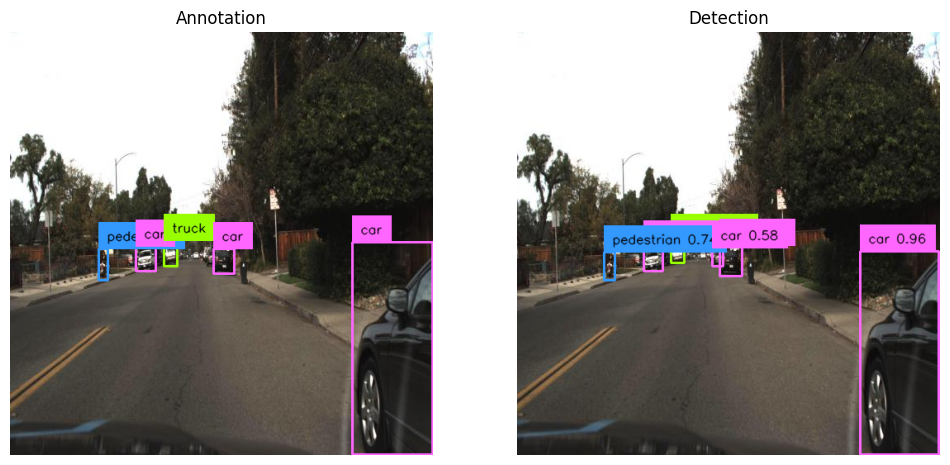

In [7]:
import supervision as sv
from PIL import Image

path, image, annotations = val_ds[110]
image = Image.open(path)

detections = model.predict(image, threshold=0.5)

text_scale = sv.calculate_optimal_text_scale(resolution_wh=image.size)
thickness = sv.calculate_optimal_line_thickness(resolution_wh=image.size)
color = sv.ColorPalette.from_hex([
    "#ffff00", "#ff9b00", "#ff66ff", "#3399ff", "#ff66b2", "#ff8080",
    "#b266ff", "#9999ff", "#66ffff", "#33ff99", "#66ff66", "#99ff00"
])

bbox_annotator = sv.BoxAnnotator(color=color,thickness=thickness)
label_annotator = sv.LabelAnnotator(
    color=color, 
    text_color=sv.Color.BLACK,
    text_scale=text_scale)

annotations_labels = [
    f"{val_ds.classes[class_id]}"
    for class_id
    in annotations.class_id
]

detections_labels = [
    f"{val_ds.classes[class_id]} {confidence:.2f}"
    for class_id, confidence
    in zip(detections.class_id, detections.confidence)
]

annotation_image = image.copy()
annotation_image = bbox_annotator.annotate(annotation_image, annotations)
annotation_image = label_annotator.annotate(annotation_image, annotations, annotations_labels)

detections_image = image.copy()
detections_image = bbox_annotator.annotate(detections_image, detections)
detections_image = label_annotator.annotate(detections_image, detections, detections_labels)

sv.plot_images_grid(images=[annotation_image, detections_image], grid_size=(1, 2), titles=["Annotation", "Detection"])

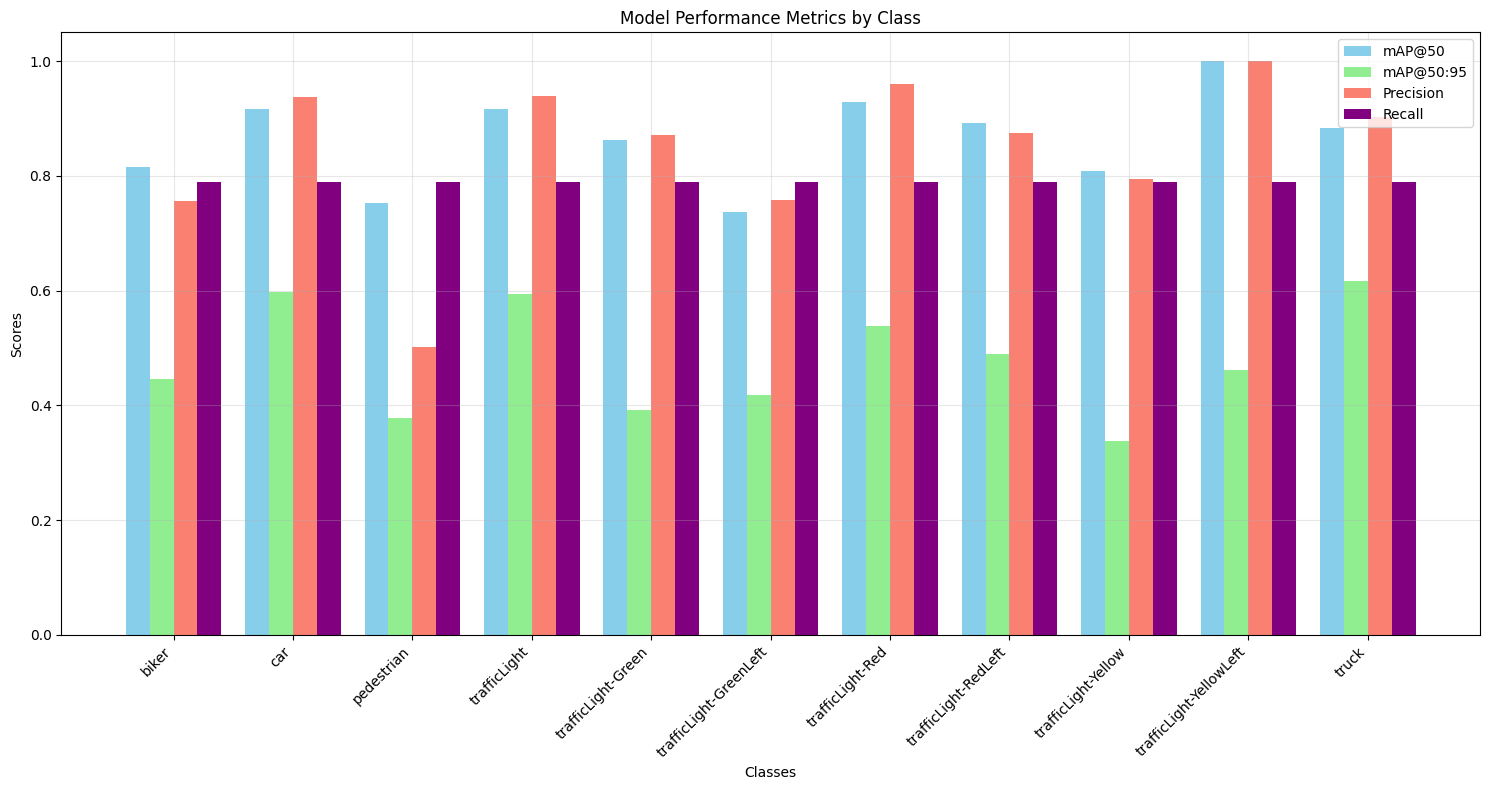

In [11]:
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the results
with open('output_large_2/results.json', 'r') as f:
    results = json.load(f)

# Extract validation results
valid_results = results['class_map']['valid']

# Create a DataFrame
data = []
for item in valid_results:
    if item['class'] != 'all':  # Exclude the 'all' summary row
        data.append({
            'class': item['class'],
            'mAP@50': item['map@50'],
            'mAP@50:95': item['map@50:95'],
            'Precision': item['precision'],
            'Recall': item['recall']
        })

df = pd.DataFrame(data)

# Create the visualization
plt.figure(figsize=(15, 8))
x = range(len(df['class']))

# Plot bars
width = 0.2
plt.bar(x, df['mAP@50'], width, label='mAP@50', color='skyblue')
plt.bar([i + width for i in x], df['mAP@50:95'], width, label='mAP@50:95', color='lightgreen')
plt.bar([i + width * 2 for i in x], df['Precision'], width, label='Precision', color='salmon')
plt.bar([i + width * 3 for i in x], df['Recall'], width, label='Recall', color='purple')

# Customize the plot
plt.xlabel('Classes')
plt.ylabel('Scores')
plt.title('Model Performance Metrics by Class')
plt.xticks([i + width * 1.5 for i in x], df['class'], rotation=45, ha='right')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)

# Adjust layout to prevent label cutoff
plt.tight_layout()
plt.show()

In [ ]:
import torch
import supervision as sv
from PIL import Image
import numpy as np


def callback(image: np.ndarray) -> sv.Detections:
    results = model.predict(image)

    detections = sv.Detections.from_r(
        transformers_results=results,
        id2label=model.config.id2label
    )
    
    return detections

confusion_matrix = sv.ConfusionMatrix.benchmark(
   dataset = val_ds,
   callback = callback
)

confusion_matrix.plot()